# Лабораторная работа №2. Классификация

Датасет Titanic (Kaggle). Задача — предсказать `Survived`: выжил пассажир (1) или нет (0). Основная метрика — F1 для класса `Survived = 1` (порог > 0.70), дополнительные — Accuracy, Precision, Recall.

Работа из двух частей: **разделы 1–8** — основная лабораторная на датасете Titanic (Yasser H.), **раздел 9** — модель для соревнования на Kaggle, где в данных нет имён, билетов и кают.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, cross_validate, cross_val_predict
from sklearn.ensemble import VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set(style="whitegrid")
RANDOM_STATE = 42
F1_THRESHOLD = 0.70

## 1. Знакомство с данными

In [2]:
data = pd.read_csv("Titanic-Dataset.csv")

print("размер:", data.shape)
print("полных дубликатов строк:", data.duplicated().sum())
print("дубликатов без учёта PassengerId:", data.drop(columns="PassengerId").duplicated().sum())
data.head()

размер: (891, 12)
полных дубликатов строк: 0
дубликатов без учёта PassengerId: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
info = pd.DataFrame({
    "тип": data.dtypes.astype(str),
    "пропусков": data.isna().sum(),
    "% пропусков": (data.isna().mean() * 100).round(1),
    "уникальных": data.nunique(),
})
info

,тип,пропусков,% пропусков,уникальных
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


- 891 пассажир, 12 столбцов, дубликатов нет.
- Числовые: `Age`, `Fare`, `SibSp` (братья/сёстры/супруги на борту), `Parch` (родители/дети). Категориальные: `Sex`, `Embarked` (порт посадки), `Pclass` (класс билета 1–3, упорядоченный).
- **Пропуски:** `Age` — 177 (19.9%), `Cabin` — 687 (77.1%), `Embarked` — 2.
- **Признаки-идентификаторы:** `PassengerId` и `Name` уникальны у каждого пассажира, `Ticket` — 681 значение на 891 строку, `Cabin` — почти уникальный номер каюты. На них модель может просто запомнить конкретных людей.

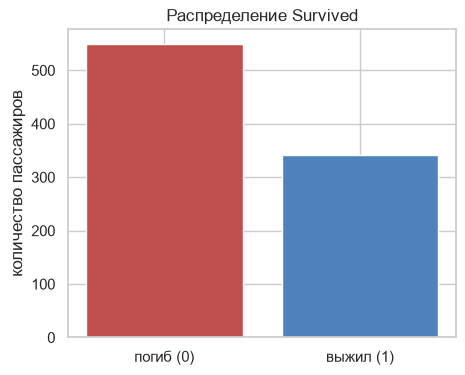

{0: 549, 1: 342}
доля выживших: 0.384


In [4]:
counts = data["Survived"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(["погиб (0)", "выжил (1)"], counts.values, color=["#c0504d", "#4f81bd"])
plt.ylabel("количество пассажиров")
plt.title("Распределение Survived")
plt.show()

print(counts.to_dict())
print("доля выживших:", round(data["Survived"].mean(), 3))

- Выживших 38.4%, погибших 61.6% — классы несбалансированы. Модель «все погибли» уже даёт Accuracy ≈ 0.62, поэтому Accuracy одной недостаточно, нужен F1. При разбиении нужна стратификация.

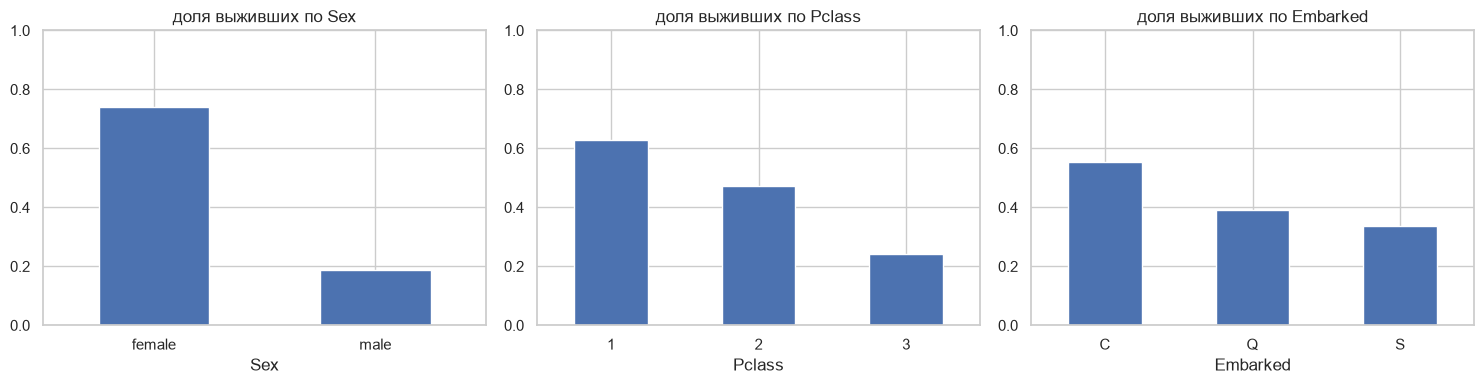

{'female': 0.742, 'male': 0.189}
{1: 0.63, 2: 0.473, 3: 0.242}
{'C': 0.554, 'Q': 0.39, 'S': 0.337}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    data.groupby(col)["Survived"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"доля выживших по {col}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(data.groupby("Sex")["Survived"].mean().round(3).to_dict())
print(data.groupby("Pclass")["Survived"].mean().round(3).to_dict())
print(data.groupby("Embarked")["Survived"].mean().round(3).to_dict())

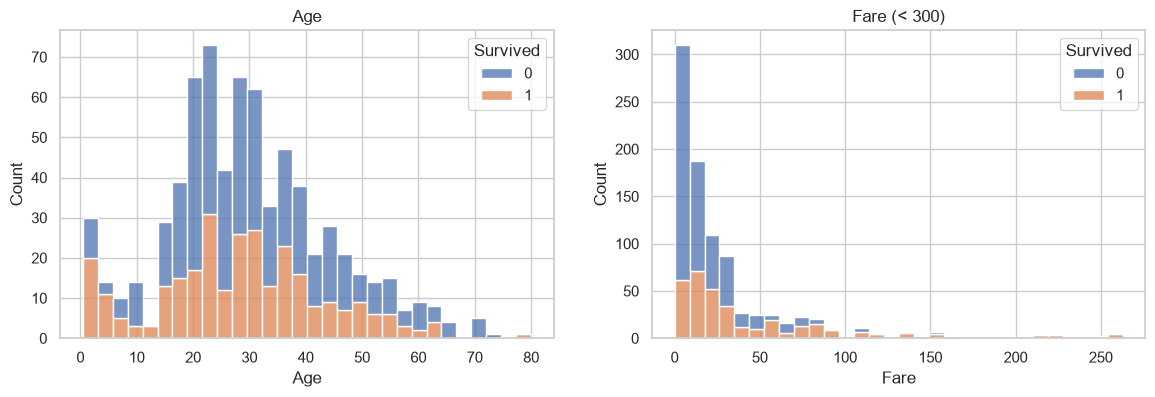

Age
(0, 12]      0.580
(12, 18]     0.429
(18, 40]     0.388
(40, 60]     0.391
(60, 100]    0.227
Name: Survived, dtype: float64
корреляция Fare и Pclass: -0.55


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=data, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[0])
axes[0].set_title("Age")
sns.histplot(data=data[data["Fare"] < 300], x="Fare", hue="Survived", bins=30, multiple="stack", ax=axes[1])
axes[1].set_title("Fare (< 300)")
plt.show()

print(data.groupby(pd.cut(data["Age"], [0, 12, 18, 40, 60, 100]), observed=True)["Survived"].mean().round(3))
print("корреляция Fare и Pclass:", round(data["Fare"].corr(data["Pclass"]), 2))

- **Пол** — самый сильный фактор: женщины выжили в 74% случаев, мужчины — в 19% (правило «сначала женщины и дети»).
- **Класс:** 1-й — 63%, 2-й — 47%, 3-й — 24%.
- **Возраст:** дети до 12 лет выживали чаще (58%), пожилые 60+ — реже (23%).
- **Fare** положительно связан с выживанием, но во многом через класс (корреляция с `Pclass` −0.55). Распределение `Fare` сильно скошено (до 512).
- У `Embarked = C` выживаемость выше (55%), но скорее потому, что там садилось больше пассажиров 1-го класса.

### Признак из имени
Само имя уникально, но в нём есть обращение (`Mr`, `Mrs`, `Miss`, `Master`, …) — оно несёт пол, возраст (Master — мальчик) и семейное положение. Выделяю его в признак `Title`, редкие обращения объединяю в `Rare`.

In [7]:
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0]
print(data["Title"].value_counts().to_dict())

data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data["Title"] = data["Title"].where(data["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
data.groupby("Title")["Survived"].agg(["count", "mean"]).round(3)

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}


,count,mean
Title,,
Master,40,0.575
Miss,185,0.703
Mr,517,0.157
Mrs,126,0.794
Rare,23,0.348


- У `Mr` (взрослый мужчина) выжили 16%, у `Mrs`/`Miss` — 70–79%, у `Master` (мальчик) — 57%. `Title` — 5 общих категорий, пассажира он не идентифицирует.  
Таким образом, мальчики выживали в 3.5 раза чаще, чем взрослые мужчины.


### Проверка: что будет, если взять идентификатор

In [8]:
# отдельное временное разбиение, только для этой проверки
Xa, Xb, ya, yb = train_test_split(data[["PassengerId"]], data["Survived"], test_size=0.2,
                                  random_state=RANDOM_STATE, stratify=data["Survived"])
tree_id = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xa, ya)
print("дерево только на PassengerId: F1 train =", round(f1_score(ya, tree_id.predict(Xa)), 3),
      "| F1 test =", round(f1_score(yb, tree_id.predict(Xb)), 3))

дерево только на PassengerId: F1 train = 1.0 | F1 test = 0.403


- На train F1 = 1.0, на test — 0.40: дерево запомнило номера пассажиров, а не закономерность. Поэтому `PassengerId`, `Name`, `Ticket`, `Cabin` в модели не беру (`Cabin` ещё и пропущен у 77%).
- Утечки целевой переменной в данных нет: все признаки известны на момент посадки.  

Уникальные признаки позволяют модели запомнить конкретных пассажиров вместо того, чтобы найти общую закономерность. Это переобучение, и на новых данных модель не работает.

## 2. Подготовка данных и разбиение

In [9]:
num_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_features = ["Sex", "Embarked", "Title"]
features = num_features + cat_features

X = data[features]
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, "test:", X_test.shape)
print("доля выживших: train", round(y_train.mean(), 3), "| test", round(y_test.mean(), 3))

train: (712, 8) test: (179, 8)
доля выживших: train 0.383 | test 0.385


- **Разбиение** 80/20 со стратификацией по `Survived` — доля выживших одинакова в train и test (38%). `random_state=42`, все модели обучаются и оцениваются на этом разбиении.
- **Тест** используется только для финальной оценки. Гиперпараметры подбираю и лучшую модель выбираю по 5-фолдовой кросс-валидации на train.

In [10]:
def make_pipeline(model, scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), cat_features),
    ])
    return Pipeline([("prep", prep), ("model", model)])

print(list(make_pipeline(DummyClassifier(), scale=False)
           .fit(X_train, y_train).named_steps["prep"].get_feature_names_out()))

['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Rare']


**Обработка признаков:**
- `Age` — пропуски заполняю **медианой**: удалять 20% строк жалко, а медиана устойчива к выбросам.
- `Embarked` — 2 пропуска, заполняю **самым частым значением** (`S`).
- `Sex`, `Embarked`, `Title` — **One-Hot**: категории не упорядочены, кодирование числами 0/1/2 задало бы ложный порядок. Для `Sex` остаётся один столбец `Sex_male`.
- `Pclass` оставляю числом — классы упорядочены.
- Всё собрано в `Pipeline`: медиана, мода и категории считаются только по train (и заново внутри каждого фолда CV), к test только применяются.

**Масштабирование:**
- деревьям (DT, RF, GB) не нужно — они делят признаки по порогам, масштаб не влияет на разбиения;
- SVM и KNN — нужно: оба считают расстояния между объектами, и без масштабирования `Fare` (до 512) задавит бинарные признаки 0/1. Для них добавляю `StandardScaler` (тоже обучается только на train).

## 3. Метрики

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}

def show_results(name, model, cv_f1=np.nan):
    """метрики на train и test, confusion matrix на test"""
    pred_test = model.predict(X_test)
    res = pd.DataFrame({"train": evaluate(y_train, model.predict(X_train)),
                        "test": evaluate(y_test, pred_test)})
    results[name] = {**res["test"], "CV F1": cv_f1}
    models[name] = model

    cm = confusion_matrix(y_test, pred_test)
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Blues", colorbar=False)
    plt.title(f"{name}: confusion matrix (test)")
    plt.grid(False)
    plt.show()
    return res.round(4)

results = {}
models = {}

Положительный класс — «выжил».
- **Accuracy** — доля верных ответов.
- **Precision** = TP / (TP + FP) — какая доля тех, кого модель назвала выжившими, правда выжила.
- **Recall** = TP / (TP + FN) — какую долю всех выживших модель нашла.
- **F1** — гармоническое среднее Precision и Recall. Высокий F1 только если обе метрики высокие, поэтому он честнее Accuracy при несбалансированных классах.

**Ошибки в контексте задачи:**
- **FP** — модель сказала «выжил», а пассажир погиб (переоценили шансы);
- **FN** — модель сказала «погиб», а пассажир выжил (пропустили выжившего).

## 4. Baseline

TN=110  FP=0  FN=69  TP=0


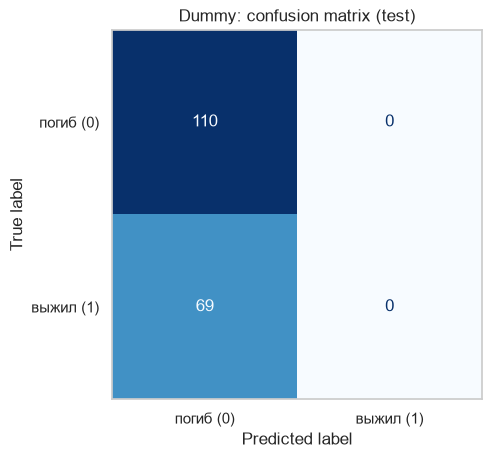

,train,test
Accuracy,0.6166,0.6145
Precision,0.0000,0.0000
Recall,0.0000,0.0000
F1,0.0000,0.0000


In [12]:
dummy = make_pipeline(DummyClassifier(strategy="most_frequent"), scale=False).fit(X_train, y_train)
show_results("Dummy", dummy)

- Dummy всегда отвечает «погиб» (самый частый класс в train). Accuracy 0.615 — это просто доля погибших в test, а Precision, Recall и F1 = 0: ни одного выжившего не найдено (FN = 69, TP = 0).
- Любая полезная модель должна быть заметно лучше, особенно по F1.

## 5. Модели
### Decision Tree
Сначала дерево без ограничений, чтобы посмотреть на переобучение.

In [13]:
dt_full = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False)
cv_full = cross_validate(dt_full, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
print("глубина (на всём train):", dt_full.fit(X_train, y_train).named_steps["model"].get_depth())
print("F1 на обучающих фолдах:", round(cv_full["train_score"].mean(), 4),
      "| F1 на валидационных фолдах (CV):", round(cv_full["test_score"].mean(), 4))

глубина (на всём train): 18
F1 на обучающих фолдах: 0.9786 | F1 на валидационных фолдах (CV): 0.6961


лучшие параметры: {'model__max_depth': 6, 'model__min_samples_leaf': 10}
CV F1: 0.7338
TN=99  FP=11  FN=23  TP=46


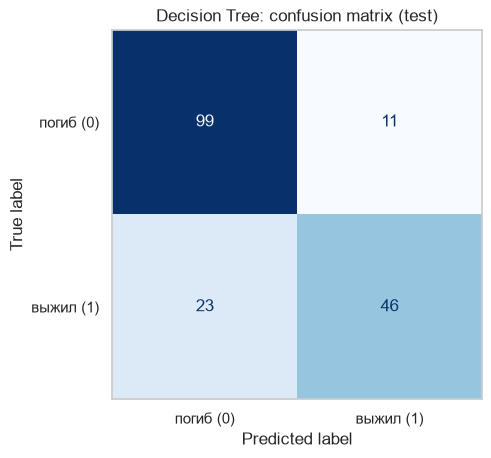

,train,test
Accuracy,0.8567,0.8101
Precision,0.8638,0.8070
Recall,0.7436,0.6667
F1,0.7992,0.7302


In [14]:
dt_search = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
    param_grid={"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]},
    cv=cv, scoring="f1", n_jobs=-1
)
dt_search.fit(X_train, y_train)
print("лучшие параметры:", dt_search.best_params_)
print("CV F1:", round(dt_search.best_score_, 4))

dt = dt_search.best_estimator_
show_results("Decision Tree", dt, dt_search.best_score_)

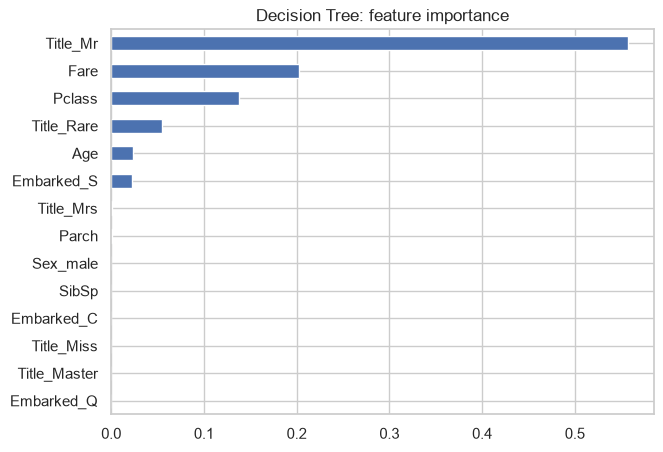

Title_Mr        0.557
Fare            0.203
Pclass          0.138
Title_Rare      0.054
Age             0.024
Embarked_S      0.022
Title_Mrs       0.001
Parch           0.001
Sex_male        0.000
SibSp           0.000
Title_Master    0.000
Embarked_Q      0.000
Embarked_C      0.000
Title_Miss      0.000
dtype: float64

In [15]:
def get_importance(model):
    names = [n.split("__")[1] for n in model.named_steps["prep"].get_feature_names_out()]
    return pd.Series(model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)

imp_dt = get_importance(dt)
imp_dt.sort_values().plot(kind="barh", figsize=(7, 5), title="Decision Tree: feature importance")
plt.show()
imp_dt.round(3)

- **Без ограничений** дерево вырастает до глубины 18. На CV видно переобучение: на обучающих фолдах F1 0.98 — оно почти запомнило их, — а на валидационных только 0.70. Ограниченное дерево на той же CV лучше (0.734). Сравнение сделано на CV по train, test здесь не используется.
- **Подобранное дерево** (`max_depth=6`, `min_samples_leaf=10`): F1 0.730 — **порог пройден**. train 0.799 → test 0.730, Accuracy 0.857 → 0.810: небольшое переобучение есть, но ограничения глубины и листа его сдерживают.
- Ошибки: FN = 23 больше, чем FP = 11 — дерево чаще пропускает выживших (Recall 0.667 при Precision 0.807).
- **Feature importance:** больше половины у `Title_Mr` (0.557) — по нему идёт первое (корневое) разбиение «взрослый мужчина или нет». Дальше `Fare` (0.203) и `Pclass` (0.138). У `Sex_male` 0: после разбиения по `Title_Mr` пол уже почти ничего не добавляет (все `Mr` — мужчины), и дерево его не выбрало.

### Random Forest

лучшие параметры: {'model__max_depth': 4, 'model__min_samples_leaf': 1}
CV F1: 0.763
TN=97  FP=13  FN=22  TP=47


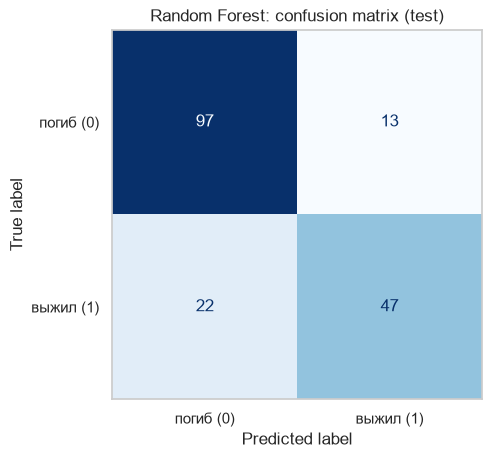

,train,test
Accuracy,0.8413,0.8045
Precision,0.8333,0.7833
Recall,0.7326,0.6812
F1,0.7797,0.7287


In [16]:
rf_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), scale=False),
    param_grid={"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="f1", n_jobs=-1
)
rf_search.fit(X_train, y_train)
print("лучшие параметры:", rf_search.best_params_)
print("CV F1:", round(rf_search.best_score_, 4))

rf = rf_search.best_estimator_
show_results("Random Forest", rf, rf_search.best_score_)

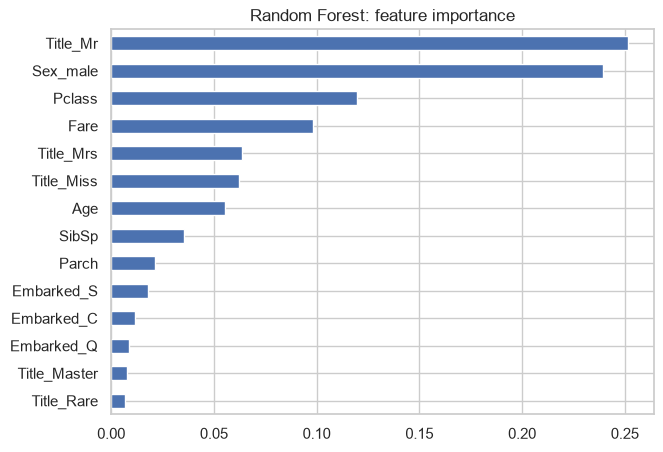

Title_Mr        0.251
Sex_male        0.239
Pclass          0.120
Fare            0.098
Title_Mrs       0.064
Title_Miss      0.062
Age             0.056
SibSp           0.036
Parch           0.021
Embarked_S      0.018
Embarked_C      0.012
Embarked_Q      0.009
Title_Master    0.008
Title_Rare      0.007
dtype: float64

In [17]:
imp_rf = get_importance(rf)
imp_rf.sort_values().plot(kind="barh", figsize=(7, 5), title="Random Forest: feature importance")
plt.show()
imp_rf.round(3)

- F1 0.729 — **порог пройден**. Разрыв train/test самый маленький из деревьев (0.780 → 0.729): усреднение 200 деревьев уменьшает разброс. Ошибок FN (22) по-прежнему больше, чем FP (13).
- **Сравнение с Decision Tree:** важность распределена равномернее. `Title_Mr` (0.251) и `Sex_male` (0.239) почти поровну — каждое дерево в узле видит случайную часть признаков, и где нет `Title_Mr`, используется `Sex`. Дальше `Pclass` (0.120) и `Fare` (0.098). Главные факторы те же, что у дерева, но лес не «обнуляет» коррелированный признак.

### Gradient Boosting

лучшие параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
CV F1: 0.7656
TN=99  FP=11  FN=21  TP=48


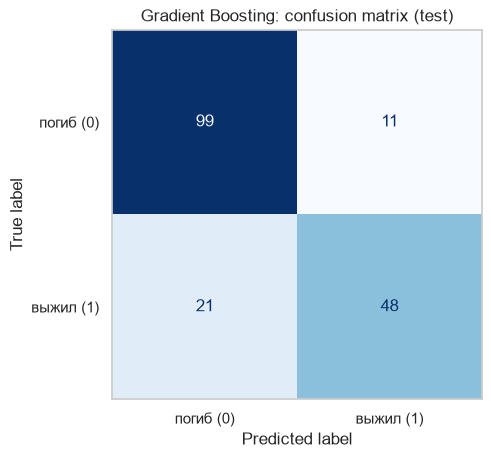

,train,test
Accuracy,0.9368,0.8212
Precision,0.9524,0.8136
Recall,0.8791,0.6957
F1,0.9143,0.7500


In [18]:
gb_search = GridSearchCV(
    make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
    param_grid={"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]},
    cv=cv, scoring="f1", n_jobs=-1
)
gb_search.fit(X_train, y_train)
print("лучшие параметры:", gb_search.best_params_)
print("CV F1:", round(gb_search.best_score_, 4))

gb = gb_search.best_estimator_
show_results("Gradient Boosting", gb, gb_search.best_score_)

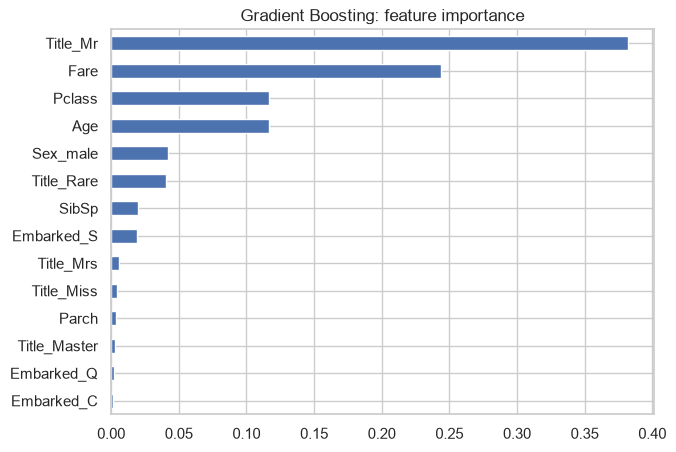

Title_Mr        0.382
Fare            0.244
Pclass          0.117
Age             0.117
Sex_male        0.042
Title_Rare      0.040
SibSp           0.020
Embarked_S      0.019
Title_Mrs       0.006
Title_Miss      0.004
Parch           0.003
Title_Master    0.003
Embarked_Q      0.002
Embarked_C      0.001
dtype: float64

In [19]:
imp_gb = get_importance(gb)
imp_gb.sort_values().plot(kind="barh", figsize=(7, 5), title="Gradient Boosting: feature importance")
plt.show()
imp_gb.round(3)

- F1 0.750 — **порог пройден**, лучше Random Forest (0.729): выше и Precision (0.814), и Recall (0.696).
- Но разрыв train/test самый большой (0.914 → 0.750): бустинг последовательно исправляет ошибки на train и сильнее под него подстраивается.
- **Сравнение с Random Forest:** на первом месте тоже `Title_Mr` (0.382), но у бустинга больше вес непрерывных `Fare` (0.244) и `Age` (0.117), а `Sex_male` почти не используется (0.042) — как и одиночное дерево, бустинг из пары `Title_Mr`/`Sex` берёт один признак. К тому же встроенная важность завышает признаки с большим числом уникальных значений (`Fare`, `Age`).

### SVM
Проверяю, нужно ли масштабирование: одна и та же модель без `StandardScaler` и с ним.

In [20]:
# сравнение на CV по train — test для этого не используется
for scale in [False, True]:
    f1 = cross_val_score(make_pipeline(SVC(random_state=RANDOM_STATE), scale=scale), X_train, y_train, cv=cv, scoring="f1")
    print("со StandardScaler:   " if scale else "без масштабирования: ", "CV F1 =", round(f1.mean(), 4))

без масштабирования:  CV F1 = 0.4443
со StandardScaler:    CV F1 = 0.7544


лучшие параметры: {'model__C': 10, 'model__gamma': 0.03}
CV F1: 0.7722
TN=99  FP=11  FN=17  TP=52


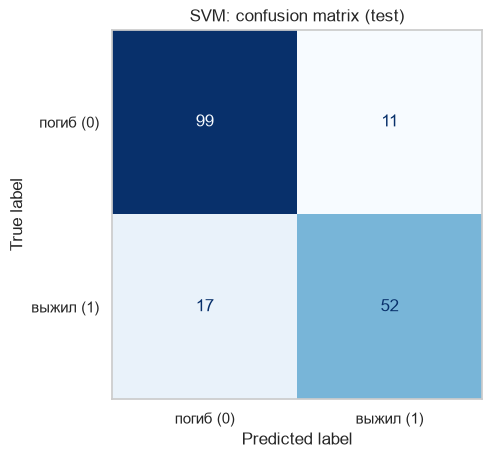

,train,test
Accuracy,0.8385,0.8436
Precision,0.8211,0.8254
Recall,0.7399,0.7536
F1,0.7784,0.7879


In [21]:
svm_search = GridSearchCV(
    make_pipeline(SVC(kernel="rbf", random_state=RANDOM_STATE), scale=True),
    param_grid={"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.03, 0.1]},
    cv=cv, scoring="f1", n_jobs=-1
)
svm_search.fit(X_train, y_train)
print("лучшие параметры:", svm_search.best_params_)
print("CV F1:", round(svm_search.best_score_, 4))

svm = svm_search.best_estimator_
show_results("SVM", svm, svm_search.best_score_)

- **Масштабирование обязательно:** на CV по train (параметры по умолчанию) без него F1 0.44, с ним 0.75. SVM ищет разделяющую поверхность с максимальным зазором, а RBF-ядро `exp(-γ‖x−z‖²)` зависит от расстояния между объектами — без масштабирования расстояние почти целиком определяется `Fare`.
- Подобранная модель (RBF, `C=10`, `gamma=0.03`): **F1 0.788, Accuracy 0.844 — лучший результат**, порог пройден. train и test почти совпадают (0.778 и 0.788) — переобучения нет.
- Ошибки: FN = 17, FP = 11, Recall выше, чем у деревьев (0.754).
- Встроенной feature importance у SVM с RBF-ядром нет.

### KNN

In [22]:
# сравнение на CV по train — test для этого не используется
for scale in [False, True]:
    f1 = cross_val_score(make_pipeline(KNeighborsClassifier(), scale=scale), X_train, y_train, cv=cv, scoring="f1")
    print("k=5 со StandardScaler:   " if scale else "k=5 без масштабирования: ", "CV F1 =", round(f1.mean(), 4))

k=5 без масштабирования:  CV F1 = 0.6001
k=5 со StandardScaler:    CV F1 = 0.7356


лучшие параметры: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
CV F1: 0.7469
TN=97  FP=13  FN=17  TP=52


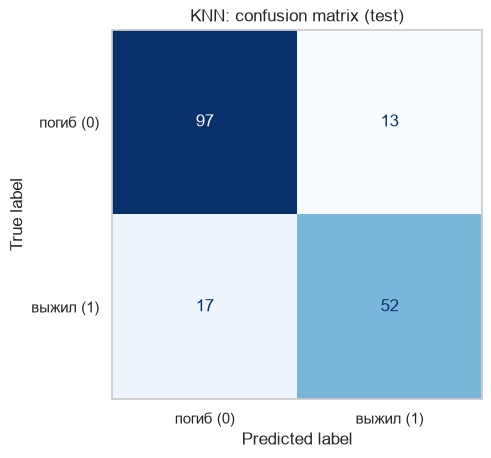

,train,test
Accuracy,0.8806,0.8324
Precision,0.8701,0.8000
Recall,0.8095,0.7536
F1,0.8387,0.7761


In [23]:
knn_search = GridSearchCV(
    make_pipeline(KNeighborsClassifier(), scale=True),
    param_grid={"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    cv=cv, scoring="f1", n_jobs=-1
)
knn_search.fit(X_train, y_train)
print("лучшие параметры:", knn_search.best_params_)
print("CV F1:", round(knn_search.best_score_, 4))

knn = knn_search.best_estimator_
show_results("KNN", knn, knn_search.best_score_)

- **Почему масштаб особенно важен:** KNN ничего не обучает — он берёт k ближайших пассажиров из train по евклидову расстоянию и голосует их классами. Если `Fare` меняется на сотни, а пол на 0/1, то «соседи» подбираются только по цене билета. Здесь это видно на CV по train: без масштабирования F1 0.60, со `StandardScaler` 0.73.
- Подобранная модель (`k=3`): F1 0.776 — **порог пройден**. train 0.841 → test 0.776: при маленьком k модель сильнее зависит от конкретных соседей (на train объект сам себе ближайший сосед).
- Ошибки: FN = 17, FP = 13.

## 6. Сравнение моделей

In [24]:
results_table = pd.DataFrame(results).T
results_table["F1 > 0.70"] = np.where(results_table["F1"] > F1_THRESHOLD, "да", "нет")
results_table.round(4)

,Accuracy,Precision,Recall,F1,CV F1,F1 > 0.70
Dummy,0.6145,0.0000,0.0000,0.0000,NaN,нет
Decision Tree,0.8101,0.8070,0.6667,0.7302,0.7338,да
Random Forest,0.8045,0.7833,0.6812,0.7287,0.7630,да
Gradient Boosting,0.8212,0.8136,0.6957,0.7500,0.7656,да
SVM,0.8436,0.8254,0.7536,0.7879,0.7722,да
KNN,0.8324,0.8000,0.7536,0.7761,0.7469,да


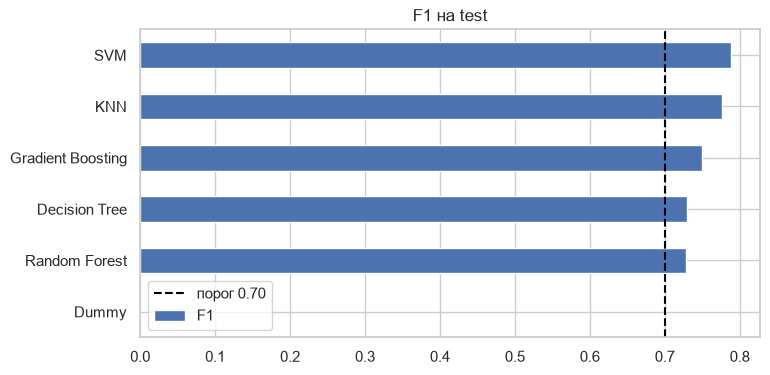

,F1 train,F1 test,разрыв
Dummy,0.0000,0.0000,0.0000
Decision Tree,0.7992,0.7302,0.0691
Random Forest,0.7797,0.7287,0.0510
Gradient Boosting,0.9143,0.7500,0.1643
SVM,0.7784,0.7879,-0.0095
KNN,0.8387,0.7761,0.0626


In [25]:
f1_train = pd.Series({name: f1_score(y_train, m.predict(X_train)) for name, m in models.items()})
overfit = pd.DataFrame({"F1 train": f1_train, "F1 test": results_table["F1"]})
overfit["разрыв"] = overfit["F1 train"] - overfit["F1 test"]

ax = results_table["F1"].sort_values().plot(kind="barh", figsize=(8, 4), title="F1 на test")
ax.axvline(F1_THRESHOLD, color="black", linestyle="--", label="порог 0.70")
ax.legend()
plt.show()
overfit.round(4)

- Все модели обучены на одном разбиении и с одинаковой предобработкой (отличие — только `StandardScaler` для SVM и KNN), параметры подобраны на одной и той же CV по train.
- **Все пять моделей лучше baseline и проходят порог F1 > 0.70.**
- **Лучшая модель — SVM** (F1 0.788): она лучшая и по CV на train (0.772), т.е. выбрана не по тесту. Дальше KNN (0.776), Gradient Boosting (0.750), Decision Tree (0.730), Random Forest (0.729).
- **Почему так:**
  - Данных мало (712 в train), признаков немного, и основную информацию несут 2–3 из них (пол/обращение, класс). Граница между классами довольно простая, и методы с гладкой границей в масштабированном пространстве (SVM, KNN) выигрывают у деревьев со «ступенчатыми» разбиениями.
  - DT и RF ограничены по глубине, чтобы не переобучаться, — у них ниже Recall (много пропущенных выживших мужчин).
  - GB сильнее подстраивается под train (разрыв 0.16), поэтому его преимущество над лесом на тесте небольшое.
  - В тесте 179 пассажиров, одна ошибка меняет F1 примерно на 0.01, поэтому порядок соседних моделей отчасти случаен.
- У всех моделей Recall ниже Precision: ошибаются чаще в сторону «погиб» (FN), т.к. этот класс преобладает.

## 7. Feature importance

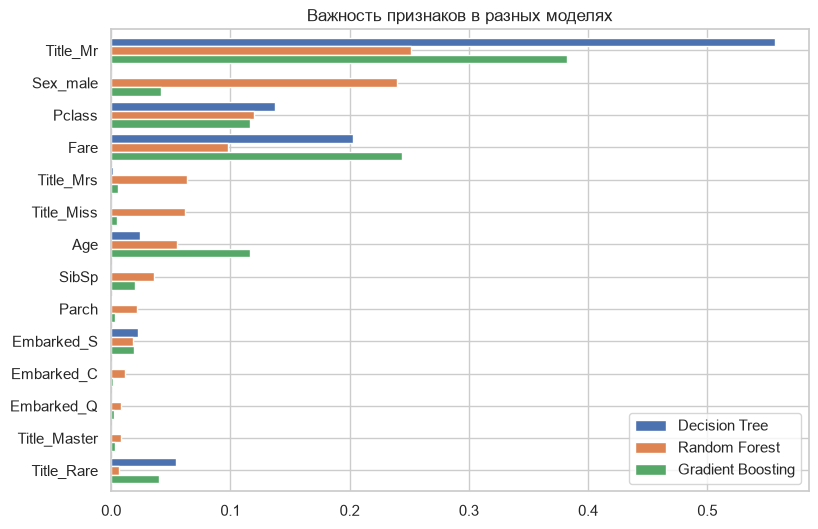

,Decision Tree,Random Forest,Gradient Boosting
Title_Mr,0.557,0.251,0.382
Sex_male,0.000,0.239,0.042
Pclass,0.138,0.120,0.117
Fare,0.203,0.098,0.244
Title_Mrs,0.001,0.064,0.006
Title_Miss,0.000,0.062,0.004
Age,0.024,0.056,0.117
SibSp,0.000,0.036,0.020
Parch,0.001,0.021,0.003
Embarked_S,0.022,0.018,0.019


In [26]:
importance = pd.DataFrame({"Decision Tree": imp_dt, "Random Forest": imp_rf, "Gradient Boosting": imp_gb})
importance = importance.sort_values("Random Forest", ascending=False)

importance.plot(kind="barh", figsize=(9, 6), width=0.8)
plt.gca().invert_yaxis()
plt.title("Важность признаков в разных моделях")
plt.show()
importance.round(3)

- **Главные признаки** у всех трёх моделей: `Title_Mr`, `Sex_male`, `Pclass`, `Fare`, затем `Age`. `Embarked`, `SibSp`, `Parch` почти не важны.
- **Сравнение моделей:** все ставят на первое место `Title_Mr`. DT и GB почти не используют `Sex_male` — он дублирует `Title_Mr`; RF делит важность между ними поровну. Конкретные числа зависят от модели, но набор главных факторов один и тот же.
- **Сходится с EDA:** там сильнее всего выживаемость различалась по полу/обращению (74% против 19%) и по классу (63% против 24%), `Fare` связан с классом, а у `Embarked`, `SibSp`, `Parch` связь слабая.
- **Важный признак — не причина выживания.** Importance показывает, насколько признак полезен модели для предсказания, т.е. статистическую связь в этих данных. Например, дорогой билет не «спасал» сам по себе: `Fare` связан с классом, а класс — с тем, где были каюты и как быстро пассажиры попадали к шлюпкам. Пол важен из-за правила эвакуации «сначала женщины и дети». Кроме того, при коррелированных признаках важность перетекает между ними (`Title_Mr` ↔ `Sex_male`). Данные наблюдательные — для вывода о причинности нужен эксперимент.

### Permutation importance
Встроенная `feature_importances_` считается по обучающей выборке и завышает признаки с большим числом уникальных значений (`Fare`, `Age`). Permutation importance устроена иначе: перемешиваем один столбец и смотрим, насколько падает F1. Её можно посчитать для любой модели, в том числе для SVM, у которой встроенной важности нет. Считаю по исходным столбцам (до One-Hot), поэтому `Title`, `Sex` и `Embarked` идут целиком.

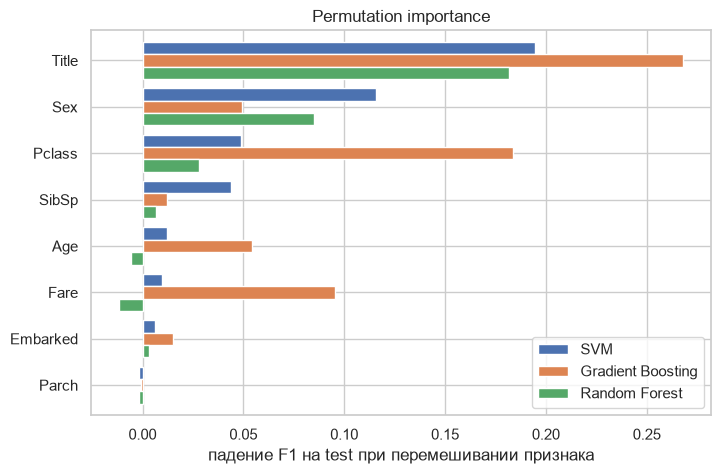

,SVM,Gradient Boosting,Random Forest
Title,0.195,0.268,0.182
Sex,0.116,0.049,0.085
Pclass,0.049,0.184,0.028
SibSp,0.044,0.012,0.007
Age,0.012,0.054,-0.005
Fare,0.010,0.095,-0.011
Embarked,0.006,0.015,0.003
Parch,-0.002,-0.001,-0.002


In [27]:
perm = {}
for name in ["SVM", "Gradient Boosting", "Random Forest"]:
    r = permutation_importance(models[name], X_test, y_test, scoring="f1",
                               n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm).sort_values("SVM", ascending=False)

perm.plot(kind="barh", figsize=(8, 5), width=0.8)
plt.gca().invert_yaxis()
plt.xlabel("падение F1 на test при перемешивании признака")
plt.title("Permutation importance")
plt.show()
perm.round(3)

- Permutation importance подтверждает главное: сильнее всего F1 падает без `Title` и `Sex`, затем без `Pclass`. Пол и обращение дублируют друг друга, поэтому перемешивание одного из них частично компенсируется другим, и их важность по отдельности занижена.
- У `Fare` и `Age` здесь важность заметно ниже, чем во встроенной у бустинга: бустинг использовал их в основном для «подгонки» под train.
- `Embarked` и `Parch` почти ни на что не влияют (значения около нуля, отрицательные — это шум). `SibSp` заметен только у SVM (~0.04): RBF-ядро использует его в сочетании с другими признаками, деревья — почти нет.

## 8. Анализ ошибок (SVM)

{'верно': 151, 'FN': 17, 'FP': 11}


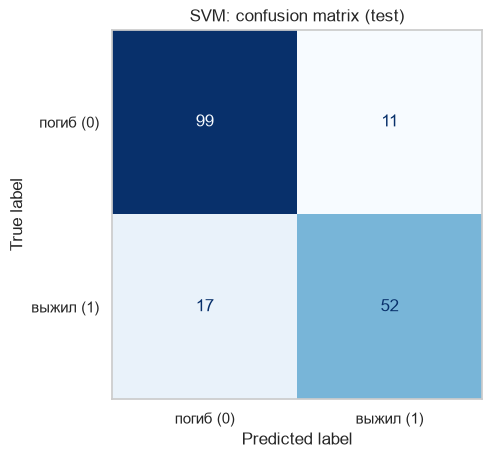

доля FN среди реально выживших: 0.246
доля FP среди реально погибших: 0.1
          n  доля выживших  FP  FN  доля ошибок
Sex                                            
female   61           0.74  10   0         0.16
male    118           0.20   1  17         0.15 

          n  доля выживших  FP  FN  доля ошибок
Pclass                                         
1        45           0.56   2   9         0.24
2        34           0.59   1   2         0.09
3       100           0.24   8   6         0.14 

          n  доля выживших  FP  FN  доля ошибок
Title                                          
Master    9           0.67   0   0         0.00
Miss     41           0.68   7   0         0.17
Mr      105           0.17   0  17         0.16
Mrs      19           0.84   3   0         0.16
Rare      5           0.20   1   0         0.20 

             n  доля выживших  FP  FN  доля ошибок
age_group                                         
0-12        14           0.50   1   0         0.07

In [28]:
test = data.loc[X_test.index].copy()
test["pred"] = svm.predict(X_test)
test["error"] = np.select([test["pred"] == test["Survived"], test["pred"] == 1], ["верно", "FP"], "FN")
print(test["error"].value_counts().to_dict())

cm = confusion_matrix(y_test, test["pred"])
ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Blues", colorbar=False)
plt.title("SVM: confusion matrix (test)")
plt.grid(False)
plt.show()
print("доля FN среди реально выживших:", round(cm[1, 0] / cm[1].sum(), 3))
print("доля FP среди реально погибших:", round(cm[0, 1] / cm[0].sum(), 3))

test["age_group"] = pd.cut(test["Age"], [0, 12, 18, 40, 60, 100], labels=["0-12", "13-18", "19-40", "41-60", "60+"])
test["age_group"] = test["age_group"].cat.add_categories("нет данных").fillna("нет данных")

def errors_by(col):
    g = test.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(),
                         "доля выживших": g["Survived"].mean(),
                         "FP": g["error"].apply(lambda e: (e == "FP").sum()),
                         "FN": g["error"].apply(lambda e: (e == "FN").sum()),
                         "доля ошибок": g["error"].apply(lambda e: (e != "верно").mean())}).round(2)

for col in ["Sex", "Pclass", "Title", "age_group"]:
    print(errors_by(col), "\n")

- Верно 151 из 179. **FN = 17 больше, чем FP = 11** — модель чаще пропускает выживших: из 69 реально выживших не нашла 25%, а из 110 погибших ошибочно «спасла» только 10%.
- **Ошибки делятся по полу:** у мужчин почти все ошибки — FN (17 из 18), у женщин — только FP (10 из 10). Модель фактически выучила правило «женщина/ребёнок — выжил, взрослый мужчина — погиб» и ошибается на исключениях: выживших мужчинах `Mr` (их в тесте 17%) и погибших женщинах.
- **Чаще всего ошибается в 1-м классе** (24% ошибок, почти все FN — выжившие мужчины 1-го класса) и в группе **19–40 лет** (20%). Для 2-го класса и детей ошибок мало, у `Master` — ни одной.

In [29]:
cols = ["Name", "Sex", "Age", "Pclass", "Title", "SibSp", "Parch", "Fare", "Embarked", "Survived", "pred"]
test[test["error"] == "FP"][cols].head(5)

,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,Survived,pred
297,"Allison, Miss. Helen Loraine",female,2.0,1,Miss,1,2,151.5500,S,0,1
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,Mrs,1,0,9.4750,S,0,1
564,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,Miss,0,0,8.0500,S,0,1
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,Miss,0,0,7.6292,Q,0,1
578,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,3,Mrs,1,0,14.4583,C,0,1


In [30]:
test[test["error"] == "FN"][cols].head(5)

,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,Survived,pred
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,0,0,7.2250,C,1,0
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,Mr,1,0,52.0000,S,1,0
455,"Jalsevac, Mr. Ivan",male,29.0,3,Mr,0,0,7.8958,C,1,0
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,0,0,13.0000,S,1,0
701,"Silverthorne, Mr. Spencer Victor",male,35.0,1,Mr,0,0,26.2875,S,1,0


In [31]:
# доля выживших среди женщин по классам (вся выборка)
data[data["Sex"] == "female"].groupby("Pclass")["Survived"].mean().round(2)

Pclass
1    0.97
2    0.92
3    0.50
Name: Survived, dtype: float64

**Разбор ошибок:**
- **FP — женщины 3-го класса** (Ahlin, Meanwell, O'Sullivan, Caram): среди женщин 1–2 класса выжили 92–97%, а в 3-м — только 50%. Модель по полу и обращению ставит им «выжил», но для 3-го класса это угадывание наполовину.
- **Helen Allison (FP, 2 года, 1-й класс):** девочка из 1-го класса — по всем признакам должна была выжить. В датасете это единственный погибший ребёнок до 12 лет из 1-го класса (остальные трое выжили, в том числе её брат Hudson Allison). Такой исход по имеющимся признакам предсказать нельзя.
- **FN — мужчины `Mr`** (Leeni, Taylor, Jalsevac, Williams, Silverthorne): по признакам они ничем не отличаются от погибших мужчин того же класса и возраста. Их спасение зависело от того, чего нет в данных (где находились в момент катастрофы, случай). У Williams ещё и пропущен возраст — он заполнен медианой.

### Проверка на идентифицирующие признаки

In [32]:
print("признаки модели:", [n.split("__")[1] for n in svm.named_steps["prep"].get_feature_names_out()])
for col in ["PassengerId", "Name", "Ticket", "Cabin"]:
    print(f"{col} используется: {col in features}")
print()
print("уникальных значений в train:", X_train.nunique().to_dict())
print("F1 train:", round(f1_score(y_train, svm.predict(X_train)), 4), "| F1 test:", round(results["SVM"]["F1"], 4))

признаки модели: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
PassengerId используется: False
Name используется: False
Ticket используется: False
Cabin используется: False

уникальных значений в train: {'Pclass': 3, 'Age': 85, 'SibSp': 7, 'Parch': 7, 'Fare': 226, 'Sex': 2, 'Embarked': 3, 'Title': 5}
F1 train: 0.7784 | F1 test: 0.7879


- `PassengerId`, `Name`, `Ticket`, `Cabin` в модель не входят. Используемые признаки описывают пассажира, а не идентифицируют его: у категориальных 2–5 значений, `Age` и `Fare` повторяются у многих (226 значений `Fare` на 712 пассажиров). `Title` взят из имени, но это 5 общих категорий.
- Признаков, известных только после катастрофы, нет; все преобразования обучались только на train.
- F1 на train (0.778) и test (0.788) почти одинаковы — модель не запоминает пассажиров (для сравнения: дерево на `PassengerId` — 1.0 и 0.40).
- Значит, высокое качество не связано с идентифицирующими признаками или утечкой.

## 9. Соревнование Kaggle
Рейтинг считается на закрытых 1000 объектах `test.csv`. Отличия от основной части:
- в данных соревнования есть только `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` — **нет `Name`, поэтому `Title` посчитать нельзя**;
- `train.csv` соревнования — те же 891 размеченных пассажира, что в основной части.

Самое ценное, что теряется без `Title`, — `Master`: мальчики выживали намного чаще взрослых мужчин. Поэтому добавляю признак **`Boy`** = мужчина не старше 14 лет. Он строится по одной строке из `Sex` и `Age`, без статистик по выборке, поэтому утечки нет.

Модель, её параметры и порог выбираю **только по CV на train той же части разбиения**, что и в основной части. Отложенный test смотрю один раз — как проверку, а не для выбора.

In [33]:
K_NUM = ["Pclass", "Age", "SibSp", "Parch", "Fare", "Boy"]
K_CAT = ["Sex", "Embarked"]


def make_kaggle_features(df):
    """7 признаков соревнования + Boy; каждая строка обрабатывается отдельно"""
    out = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
    out["Boy"] = ((out["Sex"] == "male") & (out["Age"] <= 14)).astype(int)  # при пропуске Age -> 0
    return out[K_NUM + K_CAT]


def make_kaggle_pipeline(model, scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))] + ([("scaler", StandardScaler())] if scale else [])
    prep = ColumnTransformer([
        ("num", Pipeline(num_steps), K_NUM),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), K_CAT),
    ])
    return Pipeline([("prep", prep), ("model", model)])


# то же разбиение, что в основной части
Xk_train, Xk_test = make_kaggle_features(data.loc[X_train.index]), make_kaggle_features(data.loc[X_test.index])
boys = make_kaggle_features(data)["Boy"] == 1
print("мальчиков до 14 лет:", boys.sum(), "| выжили:", round(data.loc[boys, "Survived"].mean(), 3),
      "| взрослые мужчины:", round(data.loc[(data["Sex"] == "male") & ~boys, "Survived"].mean(), 3))

мальчиков до 14 лет: 39 | выжили: 0.538 | взрослые мужчины: 0.164


**Кандидаты** — те же модели с параметрами, подобранными в основной части, и **ансамбль SVM + GB**: мягкое голосование, т.е. усреднение их вероятностей. SVM даёт гладкую границу, бустинг — ступенчатую по порогам признаков, ошибаются они на разных объектах, и усреднение уменьшает разброс.

**Порог.** Метка получается сравнением вероятности с порогом. Для F1 порог 0.5 не обязательно лучший: F1 считается только по классу «выжил», и при меньшем положительном классе выгодно немного снизить порог и поднять Recall. Порог выбираю по **out-of-fold** вероятностям на train (`cross_val_predict`): каждый объект предсказан моделью, которая его не видела. Беру 3 разных разбиения на фолды и усредняю F1, чтобы порог не зависел от одного случайного разбиения.

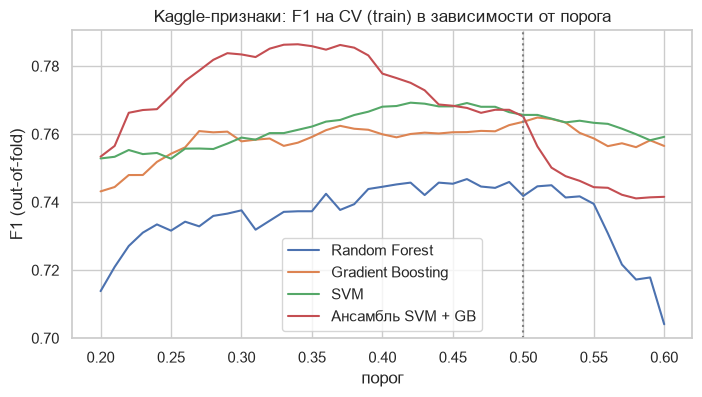

выбрана по CV: Ансамбль SVM + GB | порог: 0.34


,CV F1 @0.5,лучший порог,CV F1 @порог
Ансамбль SVM + GB,0.7652,0.34,0.7864
SVM,0.7656,0.42,0.7692
Gradient Boosting,0.7636,0.51,0.7649
Random Forest,0.7418,0.46,0.7468


In [34]:
svm_k = SVC(C=svm_search.best_params_["model__C"], gamma=svm_search.best_params_["model__gamma"],
            probability=True, random_state=RANDOM_STATE)
gb_k = GradientBoostingClassifier(**{k.split("__")[1]: v for k, v in gb_search.best_params_.items()},
                                  random_state=RANDOM_STATE)
rf_k = RandomForestClassifier(n_estimators=200, **{k.split("__")[1]: v for k, v in rf_search.best_params_.items()},
                              random_state=RANDOM_STATE)
candidates = {
    "Random Forest": make_kaggle_pipeline(rf_k, scale=False),
    "Gradient Boosting": make_kaggle_pipeline(gb_k, scale=False),
    "SVM": make_kaggle_pipeline(svm_k, scale=True),
    # масштабирование общее: SVM оно нужно, деревьям бустинга не мешает
    "Ансамбль SVM + GB": make_kaggle_pipeline(VotingClassifier([("svm", svm_k), ("gb", gb_k)], voting="soft"), scale=True),
}

THR_GRID = np.round(np.arange(0.20, 0.61, 0.01), 2)
k_curves = {}
for name, model in candidates.items():
    P = [cross_val_predict(model, Xk_train, y_train, method="predict_proba",
                           cv=StratifiedKFold(5, shuffle=True, random_state=s))[:, 1] for s in [0, 1, 2]]
    k_curves[name] = pd.Series([np.mean([f1_score(y_train, p >= t) for p in P]) for t in THR_GRID], index=THR_GRID)
k_curves = pd.DataFrame(k_curves)

ax = k_curves.plot(figsize=(8, 4), title="Kaggle-признаки: F1 на CV (train) в зависимости от порога")
ax.axvline(0.5, color="gray", linestyle=":")
ax.set_xlabel("порог"); ax.set_ylabel("F1 (out-of-fold)")
plt.show()

k_summary = pd.DataFrame({"CV F1 @0.5": k_curves.loc[0.5], "лучший порог": k_curves.idxmax(),
                          "CV F1 @порог": k_curves.max()}).sort_values("CV F1 @порог", ascending=False)
k_name = k_summary.index[0]
k_thr = k_summary.loc[k_name, "лучший порог"]
print("выбрана по CV:", k_name, "| порог:", k_thr)
k_summary.round(4)

- **Выбран ансамбль SVM + GB с порогом 0.34**: CV F1 0.786 против 0.769 у лучшей одиночной модели (SVM). Выбор сделан по CV на train.
- **Порог.** У ансамбля F1 на CV растёт при снижении порога с 0.5 до 0.34 (0.765 → 0.786): модель начинает «спасать» пограничных пассажиров, и Recall растёт быстрее, чем падает Precision. Это согласуется с теорией: для калиброванных вероятностей оптимальный по F1 порог примерно равен половине достижимого F1 (≈ 0.39), т.е. ниже 0.5. У одиночных моделей кривая почти плоская, порог им почти ничего не даёт.
- Без `Title` все модели немного хуже, чем в основной части (SVM 0.769 против 0.772 на CV), но разница небольшая: пол и возраст несут большую часть информации обращения, а `Boy` возвращает часть остального.

{'Accuracy': 0.8212, 'Precision': 0.7534, 'Recall': 0.7971, 'F1': 0.7746}
TN=92  FP=18  FN=14  TP=55


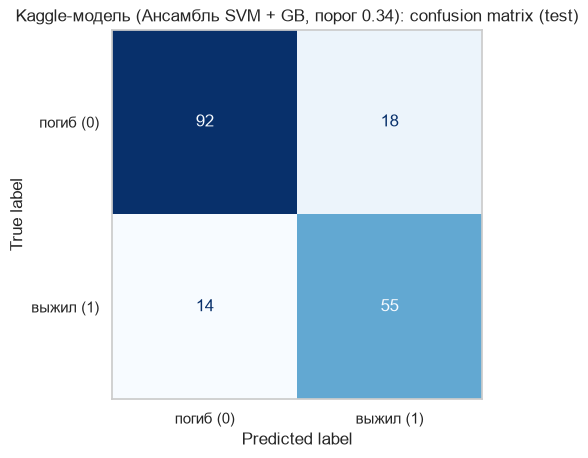

          n  FP  FN  ошибок (Kaggle)  ошибок (SVM с Title)
Sex                                                       
female   61  11   0               11                    10
male    118   7  14               21                    18 

          n  FP  FN  ошибок (Kaggle)  ошибок (SVM с Title)
Pclass                                                    
1        45   6   5               11                    11
2        34   1   2                3                     3
3       100  11   7               18                    14 

          n  FP  FN  ошибок (Kaggle)  ошибок (SVM с Title)
Title                                                     
Master    9   0   1                1                     0
Miss     41   8   0                8                     7
Mr      105   5  13               18                    17
Mrs      19   3   0                3                     3
Rare      5   2   0                2                     1 



In [35]:
# проверка на отложенном test — один раз, модель и порог уже выбраны
k_model = clone(candidates[k_name]).fit(Xk_train, y_train)
k_pred = (k_model.predict_proba(Xk_test)[:, 1] >= k_thr).astype(int)
print(pd.Series(evaluate(y_test, k_pred)).round(4).to_dict())

cm = confusion_matrix(y_test, k_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Kaggle-модель ({k_name}, порог {k_thr}): confusion matrix (test)")
plt.grid(False)
plt.show()

# где ошибается модель для Kaggle — в сравнении с SVM из основной части
k_err = data.loc[X_test.index, ["Sex", "Pclass", "Title", "Survived"]].copy()
k_err["error"] = np.select([k_pred == k_err["Survived"], k_pred == 1], ["верно", "FP"], "FN")
k_err["SVM_error"] = test["error"]
for col in ["Sex", "Pclass", "Title"]:
    g = k_err.groupby(col)
    print(pd.DataFrame({"n": g.size(),
                        "FP": g["error"].apply(lambda e: (e == "FP").sum()),
                        "FN": g["error"].apply(lambda e: (e == "FN").sum()),
                        "ошибок (Kaggle)": g["error"].apply(lambda e: (e != "верно").sum()),
                        "ошибок (SVM с Title)": g["SVM_error"].apply(lambda e: (e != "верно").sum())}), "\n")

- **На отложенном test F1 0.775** (Accuracy 0.821, Precision 0.753, Recall 0.797) — порог 0.70 пройден с запасом. Это близко к CV (0.786), т.е. оценка на CV не была завышена.
- **Профиль ошибок другой, чем у SVM из основной части:** из-за низкого порога FN меньше (14 против 17), а FP больше (18 против 11). Модель чаще «спасает» пассажиров.
- **Где ошибок больше, чем у SVM с `Title`:** в 3-м классе (18 против 14) и среди мужчин (21 против 18), в том числе мальчик `Master` с пропущенным возрастом. Без имени и возраста он неотличим от взрослого мужчины, и `Boy` = 0. Это прямое следствие того, что в данных соревнования нет `Name`.
- У женщин ошибки те же, что и раньше: погибшие женщины 3-го класса (FP).

In [36]:
# финальная модель: те же параметры и порог, обучение на всех 891 пассажирах
import os
if all(os.path.exists(f) for f in ["train.csv", "test.csv", "sample_submission.csv"]):
    k_train_full = pd.read_csv("train.csv")
    k_test_full = pd.read_csv("test.csv")
    k_sample = pd.read_csv("sample_submission.csv")
    cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]
    same = (k_train_full[cols].sort_values(cols).reset_index(drop=True)
            .equals(data[cols].sort_values(cols).reset_index(drop=True)))
    print("train.csv соревнования — те же 891 пассажир:", same)
    print("пропуски в test.csv:", k_test_full.isna().sum()[lambda s: s > 0].to_dict())

    final_model = clone(candidates[k_name]).fit(make_kaggle_features(k_train_full), k_train_full["Survived"])
    proba = final_model.predict_proba(make_kaggle_features(k_test_full))[:, 1]
    pred = pd.DataFrame({"Id": k_test_full["Id"], "Survived": (proba >= k_thr).astype(int)})
    submission = k_sample[["Id"]].merge(pred, on="Id", how="left")  # порядок Id — как в шаблоне

    # проверки формата из правил соревнования
    assert list(submission.columns) == ["Id", "Survived"] and len(submission) == len(k_sample)
    assert submission["Id"].is_unique and submission["Survived"].notna().all()
    submission["Survived"] = submission["Survived"].astype(int)
    assert submission["Survived"].isin([0, 1]).all()
    submission.to_csv("submission.csv", index=False)
    print("submission.csv:", submission.shape, "| доля ответов «выжил»:", round(submission["Survived"].mean(), 3),
          "| в train:", round(k_train_full["Survived"].mean(), 3))
else:
    print("положите train.csv, test.csv и sample_submission.csv с Kaggle рядом с ноутбуком")

train.csv соревнования — те же 891 пассажир: True
пропуски в test.csv: {'Age': 161}
submission.csv: (1000, 2) | доля ответов «выжил»: 0.416 | в train: 0.384


- Финальная модель — тот же ансамбль с теми же параметрами и порогом, но обучен на всех 891 пассажирах `train.csv`: модель и порог уже выбраны, а больше данных для обучения — лучше на закрытом тесте.
- Посылка: `Id,Survived`, 1000 строк в порядке `sample_submission.csv`, без пропусков и повторов, только 0/1 — всё проверяется `assert`.
- Ожидаемый результат на Kaggle — около 0.78 (CV 0.786, отложенный test 0.775). Но закрытый тест синтетический, а публичная часть рейтинга — всего 300 объектов, поэтому реальное значение может отличаться на несколько сотых.

### Методы и источники
- **Данные:** Titanic Dataset (Yasser H., Kaggle, лицензия CC0) — файлы соревнования `train.csv`, `test.csv`, `sample_submission.csv`.
- **Признаки:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` и производный `Boy` (мужчина ≤ 14 лет). Пропуски чисел — медиана, категорий — мода, категории — One-Hot, числа — `StandardScaler`; всё в `Pipeline`.
- **Модель:** мягкое голосование `SVC` (RBF, параметры из раздела 5) и `GradientBoostingClassifier` (параметры из раздела 5), порог 0.34.
- **Выбор модели и порога:** стратифицированная 5-fold CV на train-части (`random_state=42`), out-of-fold вероятности по 3 разбиениям; `test.csv` использован только для прогноза.
- **Библиотеки:** pandas, numpy, scikit-learn, matplotlib, seaborn.

## Итоги
- Из признаков исключены идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`), из имени выделено обращение `Title`. Пропуски `Age` — медиана, `Embarked` — мода, категории — One-Hot; всё в `Pipeline`, обучается только на train.
- Главные факторы выживания: пол/обращение, класс, стоимость билета, возраст (подтверждено и встроенной, и permutation importance).
- Dummy baseline: Accuracy 0.615, F1 0. **Все пять моделей проходят порог F1 > 0.70:** SVM 0.788, KNN 0.776, Gradient Boosting 0.750, Decision Tree 0.730, Random Forest 0.729.
- Лучшая модель — **SVM (RBF): F1 0.788, Accuracy 0.844, Precision 0.825, Recall 0.754**, выбрана по CV на train.
- Масштабирование критично для SVM (CV F1 0.44 → 0.75) и KNN (0.60 → 0.73), деревьям не нужно.
- Модель ошибается на исключениях из правила «женщины и дети»: пропускает выживших мужчин (FN) и ошибается на погибших женщинах 3-го класса (FP). Утечки и запоминания пассажиров нет.
- **Kaggle:** без `Name` модель строится на 7 признаках + `Boy`. Ансамбль SVM + GB с порогом 0.34, выбранный по CV: CV F1 0.786, на отложенном test 0.775; финальная модель обучена на всех 891 пассажирах.